In [1]:
import numpy as np
import scipy.stats as stats
import scipy.stats.qmc as qmc
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpyro as npr
import jax
import os, sys

/mnt/c/Users/Silha/Desktop/Projects/TUD/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
LHS_SIZE = 100
RANDOM_SEED = 42
DIMENSIONS = 2

In [3]:
np.random.seed(RANDOM_SEED)

In [4]:
lhs = qmc.LatinHypercube(d=DIMENSIONS, seed=RANDOM_SEED)
lhs_samples = lhs.random(n=LHS_SIZE)
print(lhs_samples[0])

[0.98226044 0.19561122]


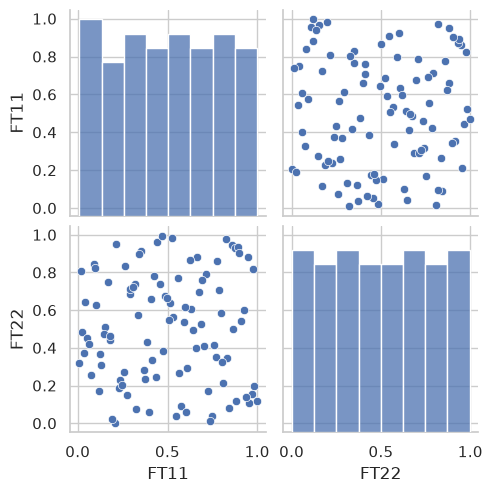

In [5]:
# visualize the LHS design
sns.set_theme(style="whitegrid")
# 
seaborn_plot = sns.pairplot(pd.DataFrame(lhs_samples, columns=["FT11", "FT22"]))


In [7]:
# load the distributions properties from the CSV file
prior_properties = pd.read_csv("mcmc_inputs/prior_params_concrete.csv")
prior_properties.head()

def round_to_n_valid_digits(value, n):
    """Round a value to n valid digits."""
    value = np.asarray(value)
    shape = value.shape
    value = value.flatten()
    for i, v in enumerate(value):
        if v == 0:
            continue
        else:
            value[i] = np.round(v, n - int(np.floor(np.log10(np.abs(v)))) - 1)
    return value.reshape(shape)

def cube_to_cylinders_strength(cube, precision=5):
    """Estimate the cylinder strength from the cube strength using a conversion factor."""
    return round_to_n_valid_digits(cube * 0.8, precision)

dists = {}
iterdict = {r"fck_{pe1}": "FT1", r"fck_{pe2}": "FT2"}
for Component, regexp in iterdict.items():
    mean = prior_properties[prior_properties["Component"].str.startswith(regexp)]["Mean"].values
    print(f"Mean for {Component}: {mean}")
    mean = cube_to_cylinders_strength(np.mean(mean), precision=4)
    std = prior_properties[prior_properties["Component"].str.startswith(regexp)]["Std"].values
    std = cube_to_cylinders_strength(np.mean(std), precision=3)
    distribution = stats.norm(
        loc=mean,
        scale=std
    )
    dists[Component] = distribution
    
def cdf_to_samples(cdf, distribution):
    """Convert a CDF to samples from the distribution."""
    return distribution.ppf(cdf)

lhs_samples_converted = np.zeros_like(lhs_samples)
for i, Component in enumerate(list(iterdict.keys())):
    distribution = dists[Component]
    lhs_samples_converted[:, i] = cdf_to_samples(lhs_samples[:, i], distribution)
    lhs_samples_converted[:, i] = round_to_n_valid_digits(lhs_samples_converted[:, i], 5)

Mean for fck_{pe1}: [50.4  49.1  46.85]
Mean for fck_{pe2}: [78.4 80.6 78.2]


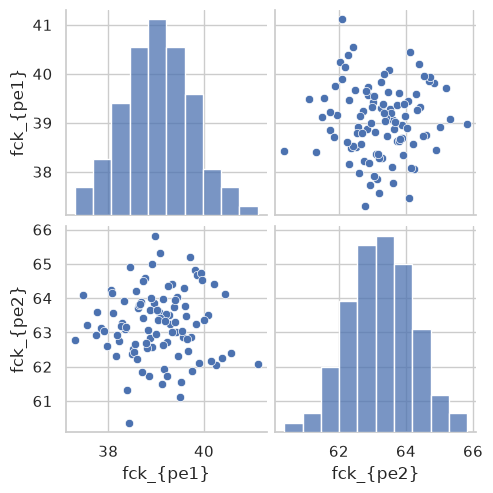

In [8]:
# plot a pairplot of the converted samples
sns.pairplot(pd.DataFrame(lhs_samples_converted, columns=list(iterdict.keys())))

In [9]:
# gen csv with the doe design
df = pd.DataFrame(lhs_samples_converted, columns=list(iterdict.keys()))
df.to_csv("doe_design.csv")

In [ ]:
# GENERATE THE CADINP INPUT FILES
DELETE_EXISTING = True
if DELETE_EXISTING:
    import shutil
    shutil.rmtree("mcmc", ignore_errors=True)

PARAMS_LIST = list(iterdict.keys())
df = pd.read_csv("doe_design.csv", index_col=0)
for i, row in df.iterrows():
    print(row)
    if i > 3: break
    os.makedirs(f"mcmc/{i}", exist_ok=True)
    with open(f"mcmc/{i}/input.dat", "w") as f:
        f.write(f"!Design {i}\n")
        for param in PARAMS_LIST:
            f.write(f"STO#{param} = {row[param]}\n")    
        


fck_{pe1}    40.555
fck_{pe2}    62.409
Name: 0, dtype: float64
fck_{pe1}    37.772
fck_{pe2}    63.610
Name: 1, dtype: float64
fck_{pe1}    38.845
fck_{pe2}    61.727
Name: 2, dtype: float64
fck_{pe1}    39.758
fck_{pe2}    61.886
Name: 3, dtype: float64
fck_{pe1}    39.809
fck_{pe2}    64.822
Name: 4, dtype: float64
